# SC4002 Project - Group 6
## Contents

- [0. Environment and run settings](#0.-Environment-and-run-settings)
- [1. Dataset and preprocessing](#1.-Dataset-and-preprocessing)
- [2. Shared reporting functions](#2.-Shared-reporting-functions)
- [3. Stage 1: joint BiLSTM and validation tuning](#3.-Stage-1:-joint-BiLSTM-and-validation-tuning)
  - [Stage 1 evaluation: validation and test](#3.6-Stage-1-evaluation:-validation-and-test)
- [4. Stage 2: BiLSTM with CRF](#4.-Stage-2:-BiLSTM-with-CRF)
  - [Stage 2 training evidence and final evaluation](#4.4-Stage-2-training-evidence-and-final-evaluation)
- [5. Stage 1 and Stage 2 results comparison](#5.-Stage-1-and-Stage-2-results-comparison)
- [6. Stage 2 error analysis](#6.-Stage-2-error-analysis)

In [36]:
import os, time, json, pickle, random, re, tarfile, zipfile, urllib.request, hashlib, platform
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torchcrf import CRF
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('main_results'); OUT.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__, '| Device:', device)
print('Full workflow: preprocess data, train both stages, reload selected checkpoints and evaluate.')

Python: 3.13.3 | PyTorch: 2.15.0+cpu | Device: cpu
Full workflow: preprocess data, train both stages, reload selected checkpoints and evaluate.


## 1. Dataset and preprocessing

Load MASSIVE 1.0 English using its original partition field. Download the official raw data and permitted GloVe word vectors when absent. Always rebuild the training-only vocabulary and encoded inputs in this execution; `processed.pkl` is an output, not a prerequisite.

### 1.1 Load the official dataset and verify the splits

In [37]:
os.makedirs("data", exist_ok=True)

if not os.path.exists("data/en-US.jsonl"):
    urllib.request.urlretrieve("https://amazon-massive-nlu-dataset.s3.amazonaws.com/amazon-massive-dataset-1.0.tar.gz", "data/massive.tar.gz")
    tar = tarfile.open("data/massive.tar.gz")
    content = tar.extractfile("1.0/data/en-US.jsonl").read()
    tar.close()
    with open("data/en-US.jsonl", "wb") as f:
        f.write(content)

In [38]:
records = []
with open("data/en-US.jsonl", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

train_raw = [r for r in records if r["partition"] == "train"]
dev_raw = [r for r in records if r["partition"] == "dev"]
test_raw = [r for r in records if r["partition"] == "test"]

print("Total:", len(records))
print("Train:", len(train_raw))
print("Dev:", len(dev_raw))
print("Test:", len(test_raw))
assert len(train_raw) == 11514
assert len(dev_raw) == 2033
assert len(test_raw) == 2974

Total: 16521
Train: 11514
Dev: 2033
Test: 2974


### 1.2 Convert annotations into tokens and BIO labels

In [39]:
def parse_annotation(annot):
    tokens = []
    tags = []
    for part in re.split(r"(\[[^\]]+\])", annot):
        if part.startswith("["):
            slot_type, span = part[1:-1].split(" : ", 1)
            for i, word in enumerate(span.split()):
                tokens.append(word)
                if i == 0:
                    tags.append("B-" + slot_type)
                else:
                    tags.append("I-" + slot_type)
        else:
            for word in part.split():
                tokens.append(word)
                tags.append("O")
    return tokens, tags


def get_spans(tokens, tags):
    spans = []
    slot_type = None
    words = []
    for word, tag in zip(tokens, tags):
        if tag.startswith("I-") and tag[2:] == slot_type:
            words.append(word)
            continue
        if slot_type is not None:
            spans.append((slot_type, " ".join(words)))
        slot_type = None
        words = []
        if tag != "O":
            slot_type = tag[2:]
            words = [word]
    if slot_type is not None:
        spans.append((slot_type, " ".join(words)))
    return spans


def process(raw):
    output = []
    for r in raw:
        tokens, tags = parse_annotation(r["annot_utt"])
        slots = re.findall(r"\[(\S+) : ([^\]]+)\]", r["annot_utt"])
        assert tokens == r["utt"].split()
        assert get_spans(tokens, tags) == slots
        output.append({"id": r["id"], "utt": r["utt"], "tokens": tokens, "tags": tags, "intent": r["intent"], "slots": slots})
    return output


train_data = process(train_raw)
dev_data = process(dev_raw)
test_data = process(test_raw)

print("Checked", len(train_data) + len(dev_data) + len(test_data), "sentences")
print(train_data[0]["tokens"])
print(train_data[0]["tags"])
print(train_data[0]["slots"])

Checked 16521 sentences
['wake', 'me', 'up', 'at', 'nine', 'am', 'on', 'friday']
['O', 'O', 'O', 'O', 'B-time', 'I-time', 'O', 'B-date']
[('time', 'nine am'), ('date', 'friday')]


### 1.3 Build the vocabulary from training data only

In [40]:
MIN_FREQ = 1

word_counts = Counter()
for d in train_data:
    word_counts.update(d["tokens"])

word2id = {"<PAD>": 0, "<UNK>": 1}
for word in sorted(word_counts):
    if word_counts[word] >= MIN_FREQ:
        word2id[word] = len(word2id)

slot_types = set()
intents = set()
for d in train_data:
    intents.add(d["intent"])
    for tag in d["tags"]:
        if tag != "O":
            slot_types.add(tag[2:])

tag2id = {"O": 0}
for s in sorted(slot_types):
    tag2id["B-" + s] = len(tag2id)
    tag2id["I-" + s] = len(tag2id)

intent2id = {}
for intent in sorted(intents):
    intent2id[intent] = len(intent2id)

id2tag = {i: t for t, i in tag2id.items()}
id2intent = {i: t for t, i in intent2id.items()}

print("Vocabulary size:", len(word2id))
print("Slot types:", len(slot_types), "BIO tags:", len(tag2id))
print("Intents:", len(intent2id))
assert len(tag2id) == 111
assert len(intent2id) == 60

Vocabulary size: 5304
Slot types: 55 BIO tags: 111
Intents: 60


### 1.4 Encode inputs and labels as arrays

In [41]:
def encode(data):
    max_len = max(len(d["tokens"]) for d in data)
    X = np.zeros((len(data), max_len), dtype=np.int64)
    Y_tags = np.full((len(data), max_len), -100, dtype=np.int64)
    Y_intent = np.zeros(len(data), dtype=np.int64)
    lengths = np.zeros(len(data), dtype=np.int64)
    for i, d in enumerate(data):
        for j in range(len(d["tokens"])):
            X[i, j] = word2id.get(d["tokens"][j], 1)
            Y_tags[i, j] = tag2id[d["tags"][j]]
        Y_intent[i] = intent2id[d["intent"]]
        lengths[i] = len(d["tokens"])
    return X, Y_tags, Y_intent, lengths


train_arrays = encode(train_data)
dev_arrays = encode(dev_data)
test_arrays = encode(test_data)

for name, arrays in [("Train", train_arrays), ("Dev", dev_arrays), ("Test", test_arrays)]:
    X, Y_tags, Y_intent, lengths = arrays
    unk = 100 * (X == 1).sum() / lengths.sum()
    print(name, "X:", X.shape, "Y_tags:", Y_tags.shape, "Y_intent:", Y_intent.shape, "unknown words:", round(unk, 2), "%")

Train X: (11514, 35) Y_tags: (11514, 35) Y_intent: (11514,) unknown words: 0.0 %
Dev X: (2033, 27) Y_tags: (2033, 27) Y_intent: (2033,) unknown words: 3.32 %
Test X: (2974, 61) Y_tags: (2974, 61) Y_intent: (2974,) unknown words: 3.51 %


### 1.5 Initialise GloVe word embeddings

In [42]:
GLOVE_DIM = 300
glove_file = "data/glove.6B." + str(GLOVE_DIM) + "d.txt"

if not os.path.exists(glove_file):
    urllib.request.urlretrieve("https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip", "data/glove.6B.zip")
    with zipfile.ZipFile("data/glove.6B.zip") as z:
        z.extract("glove.6B." + str(GLOVE_DIM) + "d.txt", "data")

np.random.seed(42)
embedding_matrix = np.random.normal(0, 0.1, (len(word2id), GLOVE_DIM)).astype(np.float32)
embedding_matrix[0] = 0
found = 0
with open(glove_file, encoding="utf-8") as f:
    for line in f:
        values = line.rstrip().split(" ")
        if values[0] in word2id:
            embedding_matrix[word2id[values[0]]] = np.array(values[1:], dtype=np.float32)
            found += 1

print("Embedding matrix:", embedding_matrix.shape)
print("Words found in GloVe:", found, "of", len(word2id) - 2)
print("Embedding parameters:", embedding_matrix.size)

Embedding matrix: (5304, 300)
Words found in GloVe: 4918 of 5302
Embedding parameters: 1591200


### 1.6 Save the processed data generated in this run

In [43]:
processed = {
    "train_data": train_data, "dev_data": dev_data, "test_data": test_data,
    "train_arrays": train_arrays, "dev_arrays": dev_arrays, "test_arrays": test_arrays,
    "word2id": word2id, "tag2id": tag2id, "id2tag": id2tag,
    "intent2id": intent2id, "id2intent": id2intent,
    "embedding_matrix": embedding_matrix,
}
with open("processed.pkl", "wb") as f:
    pickle.dump(processed, f)
print("Saved processed.pkl:", round(os.path.getsize("processed.pkl") / 1e6, 1), "MB")

Saved processed.pkl: 20.1 MB


In [44]:
P = processed
word2id = P['word2id']
tag2id, id2tag = P['tag2id'], P['id2tag']
intent2id, id2intent = P['intent2id'], P['id2intent']
embedding_matrix = P['embedding_matrix']
N_TAGS, N_INTENTS, PARAM_CAP = len(tag2id), len(intent2id), 20_000_000
def to_tensors(arrays):
    X, Y_tags, Y_intent, lengths = arrays
    return [torch.from_numpy(a) for a in (X, Y_tags, Y_intent, lengths)]

train_t = to_tensors(P["train_arrays"])
dev_t   = to_tensors(P["dev_arrays"])
test_t  = to_tensors(P["test_arrays"])
TENSORS = {'train': train_t, 'dev': dev_t, 'test': test_t}

## 2. Shared reporting functions

The slot-text scoring functions are retained for supplementary analysis. Training, checkpoint selection and the main results use the original positional span evaluators defined with each stage.

In [45]:
def intent_accuracy(gold, predicted):
    if len(gold) != len(predicted) or len(gold) == 0:
        raise ValueError("Answer lists must have equal, nonzero lengths")

    correct = 0

    for gold_label, predicted_label in zip(gold, predicted):
        if gold_label == predicted_label:
            correct += 1

    return 100 * correct / len(gold)

def decode_slots(tokens, tags):
    if len(tokens) != len(tags):
        raise ValueError("Token and tag lengths differ")

    slots = []
    current_type = None
    current_words = []

    for token, tag in list(zip(tokens, tags)) + [(None, "O")]:
        if tag.startswith("I-") and tag[2:] == current_type:
            current_words.append(token)
            continue

        if current_type is not None:
            slots.append((current_type, " ".join(current_words)))

        if tag == "O":
            current_type = None
            current_words = []
        elif tag.startswith(("B-", "I-")) and len(tag) > 2:
            current_type = tag[2:]
            current_words = [token]
        else:
            raise ValueError("Invalid tag: " + tag)

    return slots

def slot_micro_f1(gold_slots, predicted_slots):
    if len(gold_slots) != len(predicted_slots) or len(gold_slots) == 0:
        raise ValueError("Answer lists must have equal, nonzero lengths")

    tp = 0
    fp = 0
    fn = 0

    for gold, predicted in zip(gold_slots, predicted_slots):
        gold_counts = Counter(tuple(slot) for slot in gold)
        predicted_counts = Counter(tuple(slot) for slot in predicted)

        tp += sum((gold_counts & predicted_counts).values())
        fp += sum((predicted_counts - gold_counts).values())
        fn += sum((gold_counts - predicted_counts).values())

    denominator = 2 * tp + fp + fn
    f1 = 100 * 2 * tp / denominator if denominator else 0.0

    return {"slot_f1": f1, "tp": tp, "fp": fp, "fn": fn}

### 2.1 Batching, parameter counting and span conversion

In [46]:
def batches(tensors, batch_size, shuffle=False, generator=None):
    """Yield (x, tag_labels, intent_labels, lengths); padding is trimmed to the longest sequence in the batch."""
    X, Y_tags, Y_intent, lengths = tensors
    idx = torch.randperm(len(X), generator=generator) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), batch_size):
        b = idx[i:i + batch_size]
        L = int(lengths[b].max())
        yield (X[b, :L].to(device), Y_tags[b, :L].to(device), Y_intent[b].to(device), lengths[b])

def count_params(m):
    total = sum((p.numel() for p in m.parameters()))
    trainable = sum((p.numel() for p in m.parameters() if p.requires_grad))
    return (total, trainable)

def tags_to_spans(tags):
    """BIO tag strings -> set of (slot_type, start, end_exclusive)."""
    spans, cur_type, start = ([], None, None)
    for i, t in enumerate(list(tags) + ['O']):
        if t.startswith('I-') and t[2:] == cur_type:
            continue
        if cur_type is not None:
            spans.append((cur_type, start, i))
        cur_type, start = (t[2:], i) if t != 'O' else (None, None)
    return set(spans)

### 2.2 Prediction exports, checkpoint loading and learning curves

Reporting helpers do not replace the original per-stage training evaluators.

In [47]:
@torch.no_grad()
def collect_predictions(model, split):
    model.eval()
    records = []
    offset = 0
    examples = P[split + '_data']
    for x, y_tags, y_intent, lengths in batches(TENSORS[split], 256):
        intent_logits, slot_logits = model(x, lengths)
        intents = intent_logits.argmax(-1).cpu().tolist()
        if hasattr(model, 'crf'):
            paths = model.crf.decode(slot_logits, mask=(x != 0))
        else:
            paths = slot_logits.argmax(-1).cpu().tolist()
        for j in range(len(x)):
            item = examples[offset+j]
            length = int(lengths[j])
            tags = [id2tag[int(t)] for t in paths[j][:length]]
            assert len(tags) == length
            records.append(dict(index=offset+j, id=item['id'], utterance=item['utt'], tokens=item['tokens'],
                gold_intent=item['intent'], predicted_intent=id2intent[intents[j]],
                gold_tags=item['tags'], predicted_tags=tags, gold_slots=item['slots'],
                predicted_slots=decode_slots(item['tokens'], tags)))
        offset += len(x)
    assert len(records) == len(examples)
    return records

def show_run(run,title):
    frame=pd.DataFrame(run['history'])
    print(title,'|',run['mode'],'| elapsed:',round(frame.iloc[-1]['elapsed_s'],1),'seconds')
    display(frame[['epoch','train_loss','val_loss','val_intent_acc','val_slot_f1','val_score','epoch_time_s','elapsed_s','saved']].round(4))
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    axes[0].plot(frame.epoch,frame.train_loss,label='Train');axes[0].plot(frame.epoch,frame.val_loss,label='Validation');axes[0].set_title('Loss')
    axes[1].plot(frame.epoch,frame.val_intent_acc,label='Intent accuracy');axes[1].plot(frame.epoch,frame.val_slot_f1,label='Slot micro-F1');axes[1].set_title('Validation metrics (%)')
    axes[2].plot(frame.epoch,frame.train_loss_intent,label='Intent');axes[2].plot(frame.epoch,frame.train_loss_slot,label='Slot');axes[2].set_title('Training loss components')
    for ax in axes: ax.axvline(run['best_epoch'],color='gray',ls='--');ax.set_xlabel('Epoch');ax.legend()
    fig.suptitle(title);plt.tight_layout();plt.show()

def load_selected(model_class,run):
    checkpoint=torch.load(run['checkpoint'],map_location='cpu',weights_only=True);cfg=checkpoint['config']
    model=model_class(embedding_matrix,N_TAGS,N_INTENTS,cfg['hidden'],cfg['layers'],cfg['dropout']).to(device)
    model.load_state_dict(checkpoint['model_state_dict'],strict=True);model.eval()
    total,trainable=count_params(model)
    assert total==checkpoint['total_params']<=PARAM_CAP and trainable==checkpoint['trainable_params']
    return model,checkpoint



def evaluate_selected(model, checkpoint, run, label, evaluator):
    metrics, records = {}, {}
    for split in ['dev', 'test']:
        metrics[split] = evaluator(model, TENSORS[split], slot_weight=checkpoint['config'].get('slot_weight', 1.0))
        records[split] = collect_predictions(model, split)
    dev = metrics['dev']
    saved = checkpoint['val_metrics']
    for key in ['intent_acc', 'slot_f1', 'exact_match']:
        assert abs(dev[key] - saved[key]) < 1e-6
    assert abs(dev['loss'] - saved['loss']) < 1e-3
    assert abs((dev['intent_acc'] + dev['slot_f1']) / 2 - run['best_score']) < 1e-6
    print(label, 'stored validation reproduced using the original positional span scorer.')
    for split, m in metrics.items():
        print(label, split, ': intent', format(m['intent_acc'], '.2f') + '% | positional slot F1', format(m['slot_f1'], '.2f') + '%')
        with (OUT / f'{label}_{split}_predictions.jsonl').open('w', encoding='utf-8') as handle:
            for record in records[split]:
                handle.write(json.dumps(record, ensure_ascii=False) + '\n')
    return metrics, records

## 3. Stage 1: joint BiLSTM and validation tuning
The original Stage 1 architecture, CE losses and optimisation loop are retained. Fine-tuned 300-dimensional GloVe embeddings feed a two-layer bidirectional LSTM; per-token logits predict BIO slots and pooled states predict intent. Adam uses learning rate 0.001, clipping 5.0, batch size 32, and early stopping patience 8. Compare the initial configuration, hidden size 128 and dropout 0.5 using validation combined score only. Total/trainable parameter counts are checked when loading the selected model and reported in the comparison table.

### 3.1 Stage 1 model architecture

In [48]:
class Stage1Model(nn.Module):
    def __init__(self, emb_matrix, n_tags, n_intents, hidden=256, layers=2, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.emb_drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout if layers > 1 else 0)
        self.drop = nn.Dropout(dropout)
        self.slot_head = nn.Linear(2 * hidden, n_tags)
        self.intent_head = nn.Linear(4 * hidden, n_intents)

    def forward(self, x, lengths):
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        out = self.drop(out)
        slot_logits = self.slot_head(out)
        mask = (x != 0).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e9).max(dim=1).values
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        intent_logits = self.intent_head(torch.cat([mx, mean], dim=-1))
        return intent_logits, slot_logits

### 3.2 Original Stage 1 loss and evaluation

In [49]:
def stage1_compute_loss(intent_logits, slot_logits, y_intent, y_tags, slot_weight=1.0):
    loss_i = F.cross_entropy(intent_logits, y_intent)
    loss_s = F.cross_entropy(slot_logits.reshape(-1, N_TAGS), y_tags.reshape(-1), ignore_index=-100)
    return loss_i + slot_weight * loss_s, loss_i, loss_s

@torch.no_grad()
def stage1_evaluate(model, tensors, batch_size=256, slot_weight=1.0):
    """Returns loss (mean per batch), intent accuracy (%), slot micro-F1 (%), exact-match (%)."""
    model.eval()
    n = n_correct = n_exact = tp = fp = fn = 0
    loss_sum, n_batches = 0.0, 0
    for x, y_tags, y_intent, lengths in batches(tensors, batch_size):
        intent_logits, slot_logits = model(x, lengths)
        loss, _, _ = stage1_compute_loss(intent_logits, slot_logits, y_intent, y_tags, slot_weight)
        loss_sum += loss.item(); n_batches += 1
        pred_intent, pred_tags = intent_logits.argmax(-1).cpu(), slot_logits.argmax(-1).cpu()
        gold_intent, gold_tags = y_intent.cpu(), y_tags.cpu()
        for i in range(len(x)):
            L = int(lengths[i])
            pred = tags_to_spans([id2tag[int(t)] for t in pred_tags[i, :L]])
            gold = tags_to_spans([id2tag[int(t)] for t in gold_tags[i, :L]])
            tp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
            ok = int(pred_intent[i]) == int(gold_intent[i])
            n_correct += ok; n_exact += (ok and pred == gold); n += 1
    f1 = 100 * 2 * tp / max(2 * tp + fp + fn, 1)
    return {"loss": loss_sum / n_batches, "intent_acc": 100 * n_correct / n,
            "slot_f1": f1, "exact_match": 100 * n_exact / n}

### 3.3 Stage 1 training configuration and optimisation loop

In [50]:
STAGE1_CONFIG = dict(epochs=40, batch_size=32, lr=1e-3, slot_weight=1.0, hidden=256, layers=2,
              dropout=0.4, patience=8, clip=5.0, seed=SEED)
STAGE1_CKPT_PATH = "stage1_baseline_best.pt"
STAGE1_LOG_PATH  = "stage1_training_log.json"

def stage1_combined_score(m):
    return (m["intent_acc"] + m["slot_f1"]) / 2

def train_stage1(cfg=STAGE1_CONFIG, ckpt_path=STAGE1_CKPT_PATH):
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"]); random.seed(cfg["seed"])
    g = torch.Generator().manual_seed(cfg["seed"])
    model = Stage1Model(embedding_matrix, N_TAGS, N_INTENTS, cfg["hidden"], cfg["layers"], cfg["dropout"]).to(device)
    total, trainable = count_params(model)
    assert total <= PARAM_CAP
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    history, best_score, best_epoch, bad = [], -1.0, 0, 0
    t0 = time.time()
    for ep in range(1, cfg["epochs"] + 1):
        t_ep = time.time()
        model.train()
        s_tot = s_i = s_s = 0.0; nb = 0
        for x, y_tags, y_intent, lengths in batches(train_t, cfg["batch_size"], shuffle=True, generator=g):
            intent_logits, slot_logits = model(x, lengths)
            loss, li, ls = stage1_compute_loss(intent_logits, slot_logits, y_intent, y_tags, cfg["slot_weight"])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            opt.step()
            s_tot += loss.item(); s_i += li.item(); s_s += ls.item(); nb += 1

        val = stage1_evaluate(model, dev_t, slot_weight=cfg["slot_weight"])
        score = stage1_combined_score(val)
        rec = dict(epoch=ep, train_loss=s_tot / nb, train_loss_intent=s_i / nb, train_loss_slot=s_s / nb,
                   val_loss=val["loss"], val_intent_acc=val["intent_acc"], val_slot_f1=val["slot_f1"],
                   val_exact_match=val["exact_match"], val_score=score, lr=opt.param_groups[0]["lr"],
                   epoch_time_s=time.time() - t_ep, elapsed_s=time.time() - t0)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, ep, 0
            torch.save({"model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        "epoch": ep, "val_score": score, "val_metrics": val, "config": cfg,
                        "total_params": total, "trainable_params": trainable}, ckpt_path)
        else:
            bad += 1
        rec["saved"] = improved
        history.append(rec)
        print(f"Epoch {ep:02d}/{cfg['epochs']} | train loss {rec['train_loss']:.4f} | val loss {rec['val_loss']:.4f} | "
              f"val intent acc {rec['val_intent_acc']:.2f}% | val slot F1 {rec['val_slot_f1']:.2f}% | "
              f"score {score:.2f} | {rec['epoch_time_s']:.1f}s (total {rec['elapsed_s']:.0f}s)"
              + ("  <- best, checkpoint saved" if improved else ""))
        if bad >= cfg["patience"]:
            print(f"Early stopping at epoch {ep} (no dev improvement for {cfg['patience']} epochs).")
            break

    with open(STAGE1_LOG_PATH, "w") as f:
        json.dump({"config": cfg, "total_params": total, "trainable_params": trainable,
                   "best_epoch": best_epoch, "best_val_score": best_score, "history": history}, f, indent=2)
    return history, best_epoch, best_score

### 3.4 Train the Stage 1 baseline

Train the baseline separately, followed by the original Stage 1 loop for the two tuning experiments below.

In [51]:
STAGE1_LOG_PATH = 'stage1_training_log.json'
baseline_history, baseline_best_epoch, baseline_best_score = train_stage1(STAGE1_CONFIG, ckpt_path=STAGE1_CKPT_PATH)
baseline_run = dict(history=baseline_history, best_epoch=baseline_best_epoch,
    best_score=baseline_best_score, checkpoint=STAGE1_CKPT_PATH, log=STAGE1_LOG_PATH, mode='new training')

Epoch 01/40 | train loss 3.2342 | val loss 1.5894 | val intent acc 73.78% | val slot F1 39.21% | score 56.49 | 21.0s (total 21s)  <- best, checkpoint saved
Epoch 02/40 | train loss 1.3349 | val loss 1.1032 | val intent acc 81.46% | val slot F1 57.22% | score 69.34 | 21.3s (total 42s)  <- best, checkpoint saved
Epoch 03/40 | train loss 0.9292 | val loss 0.9762 | val intent acc 83.28% | val slot F1 66.41% | score 74.84 | 21.7s (total 64s)  <- best, checkpoint saved
Epoch 04/40 | train loss 0.7161 | val loss 0.8783 | val intent acc 84.80% | val slot F1 71.67% | score 78.23 | 22.0s (total 86s)  <- best, checkpoint saved
Epoch 05/40 | train loss 0.5797 | val loss 0.8874 | val intent acc 84.26% | val slot F1 72.27% | score 78.27 | 22.3s (total 108s)  <- best, checkpoint saved
Epoch 06/40 | train loss 0.4835 | val loss 0.8509 | val intent acc 85.49% | val slot F1 73.61% | score 79.55 | 20.9s (total 129s)  <- best, checkpoint saved
Epoch 07/40 | train loss 0.4071 | val loss 0.8905 | val intent

### 3.5 Baseline results and hyperparameter tuning

**Initial baseline: learning curves and validation/test results**

Stage 1: baseline | new training | elapsed: 677.9 seconds


,epoch,train_loss,val_loss,val_intent_acc,val_slot_f1,val_score,epoch_time_s,elapsed_s,saved
0,1,3.2342,1.5894,73.7826,39.2062,56.4944,20.9552,20.9552,True
1,2,1.3349,1.1032,81.4560,57.2190,69.3375,21.2713,42.2457,True
2,3,0.9292,0.9762,83.2759,66.4132,74.8446,21.6705,63.9374,True
3,4,0.7161,0.8783,84.8008,71.6679,78.2343,21.9654,85.9290,True
4,5,0.5797,0.8874,84.2597,72.2729,78.2663,22.2576,108.2052,True
5,6,0.4835,0.8509,85.4894,73.6077,79.5486,20.8586,129.0839,True
6,7,0.4071,0.8905,84.8008,74.3453,79.5730,21.1308,150.2340,True
7,8,0.3432,0.8681,85.7354,75.1883,80.4619,20.9615,171.2180,True
8,9,0.2955,0.8975,85.2927,74.2370,79.7649,20.7826,192.0207,False
9,10,0.2612,0.9498,84.9484,75.7379,80.3431,20.9165,212.9376,False


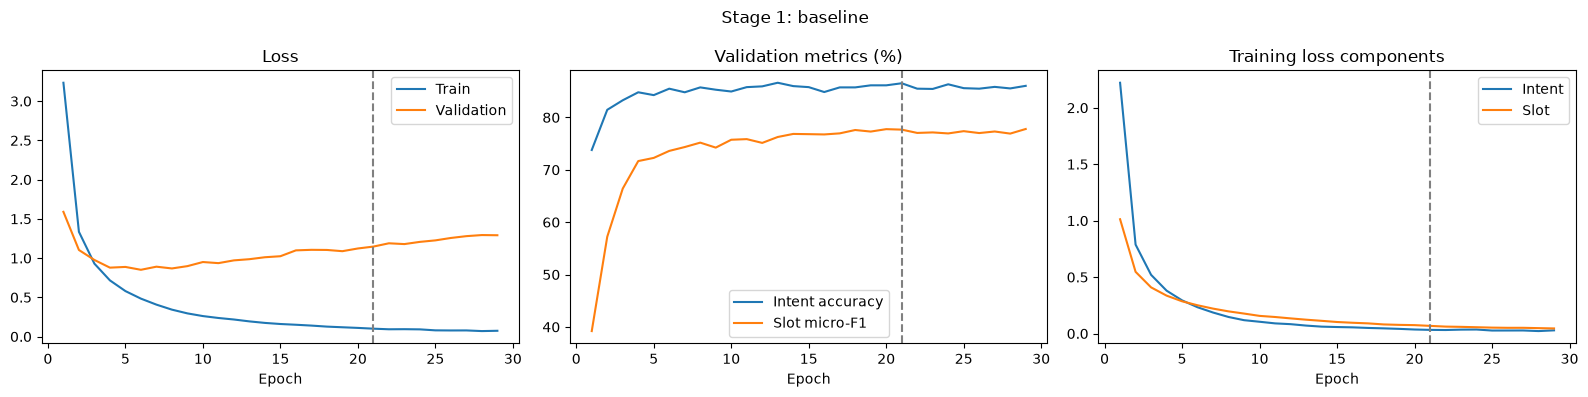

stage1_baseline stored validation reproduced using the original positional span scorer.
stage1_baseline dev : intent 86.52% | positional slot F1 77.67%
stage1_baseline test : intent 85.14% | positional slot F1 74.77%


In [52]:
show_run(baseline_run, 'Stage 1: baseline')
baseline_model, baseline_checkpoint = load_selected(Stage1Model, baseline_run)
baseline_metrics, baseline_predictions = evaluate_selected(baseline_model, baseline_checkpoint, baseline_run, 'stage1_baseline', stage1_evaluate)

#### Hyperparameter tuning: hidden size and dropout

Use the original Stage 1 tuning loop.

Epoch 01/40 | train loss 3.8493 | val loss 2.0217 | val intent acc 64.63% | val slot F1 26.60% | score 45.62 | 13.4s (total 13s)  <- best, checkpoint saved
Epoch 02/40 | train loss 1.6651 | val loss 1.3029 | val intent acc 79.64% | val slot F1 44.15% | score 61.89 | 12.9s (total 26s)  <- best, checkpoint saved
Epoch 03/40 | train loss 1.1636 | val loss 1.1186 | val intent acc 80.28% | val slot F1 57.19% | score 68.73 | 13.2s (total 39s)  <- best, checkpoint saved
Epoch 04/40 | train loss 0.9215 | val loss 0.9480 | val intent acc 84.01% | val slot F1 64.42% | score 74.22 | 15.3s (total 55s)  <- best, checkpoint saved
Epoch 05/40 | train loss 0.7550 | val loss 0.9548 | val intent acc 83.13% | val slot F1 68.61% | score 75.87 | 17.1s (total 72s)  <- best, checkpoint saved
Epoch 06/40 | train loss 0.6338 | val loss 0.9133 | val intent acc 84.01% | val slot F1 69.92% | score 76.97 | 13.6s (total 85s)  <- best, checkpoint saved
Epoch 07/40 | train loss 0.5501 | val loss 0.8914 | val intent a

,setting,best_epoch,val_intent,val_slot,val_score
0,"baseline (hidden256, drop0.4, lr1e-3)",21,86.52,77.67,82.10
1,hidden128,32,86.13,77.09,81.61
2,dropout0.5,26,86.47,78.61,82.54


Stage 1: hidden128 | new training | elapsed: 583.7 seconds


,epoch,train_loss,val_loss,val_intent_acc,val_slot_f1,val_score,epoch_time_s,elapsed_s,saved
0,1,3.8493,2.0217,64.6335,26.6001,45.6168,13.4190,13.4190,True
1,2,1.6651,1.3029,79.6360,44.1495,61.8927,12.8692,26.3006,True
2,3,1.1636,1.1186,80.2755,57.1860,68.7307,13.1793,39.4950,True
3,4,0.9215,0.9480,84.0138,64.4207,74.2173,15.2682,54.7733,True
4,5,0.7550,0.9548,83.1284,68.6097,75.8690,17.0967,71.8861,True
5,6,0.6338,0.9133,84.0138,69.9168,76.9653,13.5786,85.4766,True
6,7,0.5501,0.8914,85.2435,72.0153,78.6294,13.6028,99.0900,True
7,8,0.4845,0.8757,85.4402,72.2103,78.8253,13.6123,112.7128,True
8,9,0.4364,0.9180,84.0630,73.5026,78.7828,13.3177,126.0411,False
9,10,0.3891,0.9319,84.6040,73.7095,79.1568,13.2521,139.2934,True


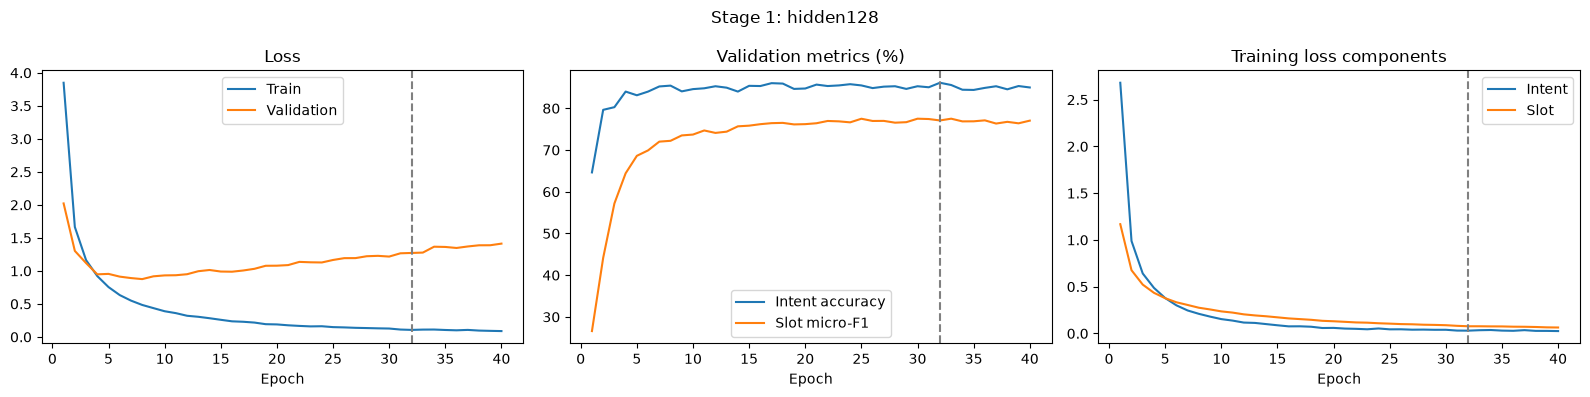

Stage 1: dropout0.5 | new training | elapsed: 729.2 seconds


,epoch,train_loss,val_loss,val_intent_acc,val_slot_f1,val_score,epoch_time_s,elapsed_s,saved
0,1,3.3315,1.7389,70.3886,35.0936,52.7411,21.2882,21.2882,True
1,2,1.4876,1.2093,78.9474,54.8515,66.8994,20.5330,41.8418,True
2,3,1.0719,1.0135,82.4397,63.6294,73.0346,20.7333,62.5945,True
3,4,0.8647,0.8952,83.6695,69.5736,76.6215,20.3116,82.9273,True
4,5,0.7169,0.8889,84.0138,70.9161,77.4650,20.5298,103.4770,True
5,6,0.6042,0.8406,85.4402,73.6333,79.5368,20.6641,124.1607,True
6,7,0.5293,0.8434,85.1451,74.2138,79.6795,20.5561,144.7395,True
7,8,0.4713,0.8371,85.5386,74.2693,79.9039,20.5906,165.3509,True
8,9,0.4104,0.8486,85.8337,74.9159,80.3748,20.4682,185.8389,True
9,10,0.3678,0.9107,84.9484,75.5427,80.2455,20.8345,206.6946,False


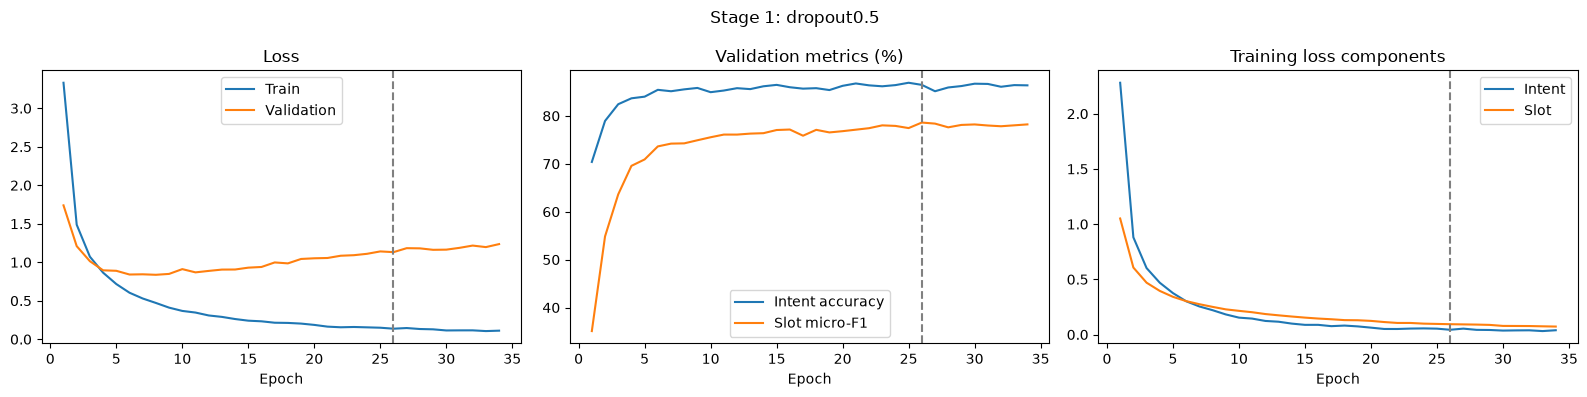

In [53]:
experiments = {
    "hidden128":  dict(hidden=128),
    "dropout0.5": dict(dropout=0.5),
}

tune_rows = [dict(setting="baseline (hidden256, drop0.4, lr1e-3)",
                  best_epoch=baseline_best_epoch,
                  val_intent=baseline_checkpoint["val_metrics"]["intent_acc"],
                  val_slot=baseline_checkpoint["val_metrics"]["slot_f1"],
                  val_score=baseline_best_score)]

for name, change in experiments.items():
    cfg = {**STAGE1_CONFIG, **change}
    STAGE1_LOG_PATH = f"tune_{name}_log.json"
    hist, be, bs = train_stage1(cfg, ckpt_path=f"tune_{name}.pt")
    tune_rows.append(dict(setting=name, best_epoch=be,
                          val_intent=hist[be-1]["val_intent_acc"],
                          val_slot=hist[be-1]["val_slot_f1"],
                          val_score=bs))

STAGE1_LOG_PATH = "stage1_training_log.json"

tune_df = pd.DataFrame(tune_rows).round(2)
display(tune_df)

# Reporting metadata only; the original tuning loop above is unchanged.
stage1_runs = {'baseline': baseline_run}
for name in experiments:
    log_path = f'tune_{name}_log.json'
    log = json.loads(Path(log_path).read_text())
    stage1_runs[name] = dict(history=log['history'], best_epoch=log['best_epoch'],
        best_score=log['best_val_score'], checkpoint=f'tune_{name}.pt', log=log_path, mode='new training')
    show_run(stage1_runs[name], f'Stage 1: {name}')


### 3.6 Stage 1 evaluation: validation and test

Reload the checkpoint selected by the highest validation combined score. First verify its validation metrics, then report intent accuracy and slot micro-F1 on the test set. The selected checkpoint epoch and total training epochs are recorded separately. No further training occurs in this evaluation step.

In [54]:
stage1_setting = max(stage1_runs, key=lambda k: stage1_runs[k]['best_score'])
stage1_run = stage1_runs[stage1_setting]
display(pd.DataFrame([dict(setting=k, best_epoch=v['best_epoch'], trained_epochs=len(v['history']),
    validation_score=v['best_score'], checkpoint=v['checkpoint']) for k, v in stage1_runs.items()]).round(2))
print('Selected Stage 1:', stage1_setting, 'using validation only.')
stage1_model, stage1_checkpoint = load_selected(Stage1Model, stage1_run)
stage1_metrics, stage1_predictions = evaluate_selected(stage1_model, stage1_checkpoint, stage1_run, 'stage1', stage1_evaluate)


,setting,best_epoch,trained_epochs,validation_score,checkpoint
0,baseline,21,29,82.10,stage1_baseline_best.pt
1,hidden128,32,40,81.61,tune_hidden128.pt
2,dropout0.5,26,34,82.54,tune_dropout0.5.pt


Selected Stage 1: dropout0.5 using validation only.
stage1 stored validation reproduced using the original positional span scorer.
stage1 dev : intent 86.47% | positional slot F1 78.61%
stage1 test : intent 84.94% | positional slot F1 75.88%


## 4. Stage 2: BiLSTM with CRF
The original Stage 2 architecture and optimisation loop are retained. The slot head adds learned CRF transitions and Viterbi decoding; slot loss is token-averaged negative log-likelihood. The encoder/intent head use dropout 0.5. Stage 2 starts from a newly initialised model, not loaded Stage 1 weights. Each stage uses its original evaluator and positional span metrics. CRF transitions are learned, not hard BIO constraints.

### 4.1 Stage 2 model architecture

In [55]:
class Stage2Model(nn.Module):
    def __init__(self, emb_matrix, n_tags, n_intents, hidden=256, layers=2, dropout=0.4):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.emb_drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, num_layers=layers, batch_first=True,
                            bidirectional=True, dropout=dropout if layers > 1 else 0)
        self.drop = nn.Dropout(dropout)
        self.slot_head = nn.Linear(2 * hidden, n_tags)
        self.intent_head = nn.Linear(4 * hidden, n_intents)
        self.crf = CRF(n_tags, batch_first=True)   # <-- NEW: learns which tag can follow which (e.g. O -> I-time is invalid)

    def forward(self, x, lengths):
        e = self.emb_drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        out = self.drop(out)
        slot_logits = self.slot_head(out)
        mask = (x != 0).unsqueeze(-1)
        mx = out.masked_fill(~mask, -1e9).max(dim=1).values
        mean = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        intent_logits = self.intent_head(torch.cat([mx, mean], dim=-1))
        return intent_logits, slot_logits

### 4.2 Original Stage 2 loss and evaluation

In [56]:
def stage2_compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, slot_weight=1.0):   # <-- CHANGED: takes model
    loss_i = F.cross_entropy(intent_logits, y_intent)
    mask = y_tags != -100                                                                   # <-- CHANGED: real words only
    loss_s = -model.crf(slot_logits, y_tags.masked_fill(~mask, 0), mask=mask, reduction="token_mean")  # <-- CHANGED: CRF loss
    return loss_i + slot_weight * loss_s, loss_i, loss_s

@torch.no_grad()
def stage2_evaluate(model, tensors, batch_size=256, slot_weight=1.0):
    """Returns loss (mean per batch), intent accuracy (%), slot micro-F1 (%), exact-match (%)."""
    model.eval()
    n = n_correct = n_exact = tp = fp = fn = 0
    loss_sum, n_batches = 0.0, 0
    for x, y_tags, y_intent, lengths in batches(tensors, batch_size):
        intent_logits, slot_logits = model(x, lengths)
        loss, _, _ = stage2_compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, slot_weight)   # <-- CHANGED
        loss_sum += loss.item(); n_batches += 1
        pred_intent = intent_logits.argmax(-1).cpu()
        pred_paths = model.crf.decode(slot_logits, mask=(x != 0))                                     # <-- CHANGED: CRF decoding
        gold_intent, gold_tags = y_intent.cpu(), y_tags.cpu()
        for i in range(len(x)):
            L = int(lengths[i])
            pred = tags_to_spans([id2tag[int(t)] for t in pred_paths[i]])                             # <-- CHANGED
            gold = tags_to_spans([id2tag[int(t)] for t in gold_tags[i, :L]])
            tp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
            ok = int(pred_intent[i]) == int(gold_intent[i])
            n_correct += ok; n_exact += (ok and pred == gold); n += 1
    f1 = 100 * 2 * tp / max(2 * tp + fp + fn, 1)
    return {"loss": loss_sum / n_batches, "intent_acc": 100 * n_correct / n,
            "slot_f1": f1, "exact_match": 100 * n_exact / n}

### 4.3 Stage 2 training configuration and optimisation loop

In [57]:
STAGE2_CONFIG = dict(epochs=40, batch_size=32, lr=1e-3, slot_weight=1.0, hidden=256, layers=2,
              dropout=0.5, patience=8, clip=5.0, seed=SEED, word_dropout=0.0, crf=True)   # <-- CHANGED (Exp 2): word dropout off, CRF on
STAGE2_CKPT_PATH = "stage2_best.pt"              # new name, keeps Stage-1 file safe
STAGE2_LOG_PATH  = "stage2_training_log.json"

def stage2_combined_score(m):
    return (m["intent_acc"] + m["slot_f1"]) / 2

def train_stage2(cfg=STAGE2_CONFIG, ckpt_path=STAGE2_CKPT_PATH):
    torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"]); random.seed(cfg["seed"])
    g = torch.Generator().manual_seed(cfg["seed"])
    model = Stage2Model(embedding_matrix, N_TAGS, N_INTENTS, cfg["hidden"], cfg["layers"], cfg["dropout"]).to(device)
    total, trainable = count_params(model)
    assert total <= PARAM_CAP
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])

    history, best_score, best_epoch, bad = [], -1.0, 0, 0
    t0 = time.time()
    for ep in range(1, cfg["epochs"] + 1):
        t_ep = time.time()
        model.train()
        s_tot = s_i = s_s = 0.0; nb = 0
        for x, y_tags, y_intent, lengths in batches(train_t, cfg["batch_size"], shuffle=True, generator=g):
            if cfg.get("word_dropout", 0) > 0:                                                    # word dropout (Exp 1); off when 0.0
                drop = (torch.rand(x.shape, device=x.device) < cfg["word_dropout"]) & (x != 0)
                x = x.masked_fill(drop, 1)                                                        # 1 = <UNK>
            intent_logits, slot_logits = model(x, lengths)
            loss, li, ls = stage2_compute_loss(model, intent_logits, slot_logits, y_intent, y_tags, cfg["slot_weight"])   # <-- CHANGED (Exp 2): pass model for CRF
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])
            opt.step()
            s_tot += loss.item(); s_i += li.item(); s_s += ls.item(); nb += 1

        val = stage2_evaluate(model, dev_t, slot_weight=cfg["slot_weight"])
        score = stage2_combined_score(val)
        rec = dict(epoch=ep, train_loss=s_tot / nb, train_loss_intent=s_i / nb, train_loss_slot=s_s / nb,
                   val_loss=val["loss"], val_intent_acc=val["intent_acc"], val_slot_f1=val["slot_f1"],
                   val_exact_match=val["exact_match"], val_score=score, lr=opt.param_groups[0]["lr"],
                   epoch_time_s=time.time() - t_ep, elapsed_s=time.time() - t0)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, ep, 0
            torch.save({"model_state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        "epoch": ep, "val_score": score, "val_metrics": val, "config": cfg,
                        "total_params": total, "trainable_params": trainable}, ckpt_path)
        else:
            bad += 1
        rec["saved"] = improved
        history.append(rec)
        print(f"Epoch {ep:02d}/{cfg['epochs']} | train loss {rec['train_loss']:.4f} | val loss {rec['val_loss']:.4f} | "
              f"val intent acc {rec['val_intent_acc']:.2f}% | val slot F1 {rec['val_slot_f1']:.2f}% | "
              f"score {score:.2f} | {rec['epoch_time_s']:.1f}s (total {rec['elapsed_s']:.0f}s)"
              + ("  <- best, checkpoint saved" if improved else ""))
        if bad >= cfg["patience"]:
            print(f"Early stopping at epoch {ep} (no dev improvement for {cfg['patience']} epochs).")
            break

    with open(STAGE2_LOG_PATH, "w") as f:
        json.dump({"config": cfg, "total_params": total, "trainable_params": trainable,
                   "best_epoch": best_epoch, "best_val_score": best_score, "history": history}, f, indent=2)
    return history, best_epoch, best_score

### 4.4 Stage 2 training evidence and final evaluation

1. Train Stage 2 using the official training split and select its highest validation combined score.
2. Display the newly generated epoch history and learning curves.
3. Reload the selected checkpoint saved by this run and verify parameter counts.
4. Reproduce validation scores and evaluate the frozen model on test using the original Stage 2 evaluator.

Report the selected checkpoint epoch separately from the total epochs trained.

Epoch 01/40 | train loss 3.2760 | val loss 1.6737 | val intent acc 71.86% | val slot F1 40.54% | score 56.20 | 28.2s (total 28s)  <- best, checkpoint saved
Epoch 02/40 | train loss 1.4074 | val loss 1.1079 | val intent acc 80.67% | val slot F1 60.84% | score 70.75 | 27.8s (total 56s)  <- best, checkpoint saved
Epoch 03/40 | train loss 0.9942 | val loss 0.9459 | val intent acc 81.80% | val slot F1 69.42% | score 75.61 | 28.4s (total 84s)  <- best, checkpoint saved
Epoch 04/40 | train loss 0.7916 | val loss 0.8524 | val intent acc 83.87% | val slot F1 74.11% | score 78.99 | 27.5s (total 112s)  <- best, checkpoint saved
Epoch 05/40 | train loss 0.6358 | val loss 0.8450 | val intent acc 83.72% | val slot F1 75.61% | score 79.66 | 28.8s (total 141s)  <- best, checkpoint saved
Epoch 06/40 | train loss 0.5458 | val loss 0.7607 | val intent acc 85.88% | val slot F1 76.63% | score 81.26 | 37.7s (total 179s)  <- best, checkpoint saved
Epoch 07/40 | train loss 0.4663 | val loss 0.7923 | val inten

,epoch,train_loss,val_loss,val_intent_acc,val_slot_f1,val_score,epoch_time_s,elapsed_s,saved
0,1,3.2760,1.6737,71.8642,40.5356,56.1999,28.1666,28.1666,True
1,2,1.4074,1.1079,80.6690,60.8361,70.7525,27.8146,55.9999,True
2,3,0.9942,0.9459,81.8003,69.4219,75.6111,28.4497,84.4732,True
3,4,0.7916,0.8524,83.8662,74.1099,78.9880,27.4843,111.9815,True
4,5,0.6358,0.8450,83.7186,75.6098,79.6642,28.7703,140.7740,True
5,6,0.5458,0.7607,85.8829,76.6276,81.2553,37.7124,178.5144,True
6,7,0.4663,0.7923,84.8992,76.3171,80.6081,29.5697,208.1084,False
7,8,0.4048,0.7740,85.5878,76.8546,81.2212,29.1829,237.2915,False
8,9,0.3538,0.7761,85.8337,78.4294,82.1316,29.2759,266.5676,True
9,10,0.3166,0.8080,85.3419,79.3508,82.3463,28.0947,294.6822,True


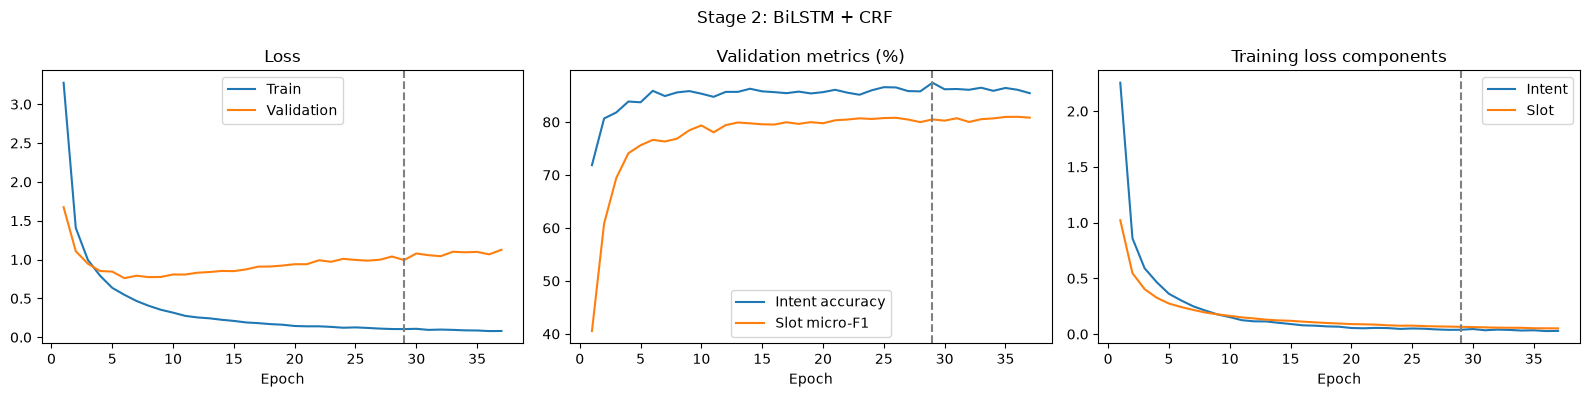

stage2 stored validation reproduced using the original positional span scorer.
stage2 dev : intent 87.41% | positional slot F1 80.48%
stage2 test : intent 84.97% | positional slot F1 78.46%


In [58]:
stage2_history, stage2_best_epoch, stage2_best_score = train_stage2(STAGE2_CONFIG, ckpt_path=STAGE2_CKPT_PATH)
stage2_run = dict(history=stage2_history, best_epoch=stage2_best_epoch,
    best_score=stage2_best_score, checkpoint=STAGE2_CKPT_PATH, log=STAGE2_LOG_PATH, mode='new training')
show_run(stage2_run, 'Stage 2: BiLSTM + CRF')
stage2_model, stage2_checkpoint = load_selected(Stage2Model, stage2_run)
stage2_metrics, stage2_predictions = evaluate_selected(stage2_model, stage2_checkpoint, stage2_run, 'stage2', stage2_evaluate)

## 5. Stage 1 and Stage 2 results comparison

Compare both models on validation and test using their original positional span scoring rules. Required metrics are percentages with two decimal places. **Number of epochs** is the total trained; **Best epoch** identifies the selected checkpoint. Joint exact match is supplementary. CE and CRF loss magnitudes are not directly comparable.

In [59]:
comparison_rows=[]
for label,run,checkpoint,metrics in [('Stage-1',stage1_run,stage1_checkpoint,stage1_metrics),('Stage-2',stage2_run,stage2_checkpoint,stage2_metrics)]:
    for split,name in [('dev','Validation'),('test','Test')]:
        comparison_rows.append(dict(Model=label,Split=name,Total_parameters=checkpoint['total_params'],
            Trainable_parameters=checkpoint['trainable_params'],Intent_accuracy=metrics[split]['intent_acc'],
            Slot_micro_F1=metrics[split]['slot_f1'],Number_of_epochs=len(run['history']),Best_epoch=run['best_epoch']))
comparison=pd.DataFrame(comparison_rows)
display(comparison.style.format({'Intent_accuracy':'{:.2f}','Slot_micro_F1':'{:.2f}'}))
comparison.to_csv(OUT/'comparison.csv',index=False,float_format='%.2f')
for key in ['intent_acc','slot_f1','exact_match']:
    print('Stage 2 minus Stage 1 test',key,':',format(stage2_metrics['test'][key]-stage1_metrics['test'][key],'+.2f'),'percentage points')
summary=dict(stage1=dict(checkpoint=stage1_run['checkpoint'],selected_epoch=stage1_run['best_epoch'],
    trained_epochs=len(stage1_run['history']),metrics=stage1_metrics),
    stage2=dict(checkpoint=stage2_run['checkpoint'],selected_epoch=stage2_run['best_epoch'],
    trained_epochs=len(stage2_run['history']),metrics=stage2_metrics),
    provenance={name:hashlib.sha256(Path(name).read_bytes()).hexdigest() for name in
        ['processed.pkl',stage1_run['checkpoint'],stage2_run['checkpoint']]},
    environment=dict(python=platform.python_version(),torch=torch.__version__,device=str(device)))
(OUT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

,Model,Split,Total_parameters,Trainable_parameters,Intent_accuracy,Slot_micro_F1,Number_of_epochs,Best_epoch
0,Stage-1,Validation,4429387,4429387,86.47,78.61,34,26
1,Stage-1,Test,4429387,4429387,84.94,75.88,34,26
2,Stage-2,Validation,4441930,4441930,87.41,80.48,37,29
3,Stage-2,Test,4441930,4441930,84.97,78.46,37,29


Stage 2 minus Stage 1 test intent_acc : +0.03 percentage points
Stage 2 minus Stage 1 test slot_f1 : +2.58 percentage points
Stage 2 minus Stage 1 test exact_match : +1.55 percentage points


1374

## 6. Stage 2 error analysis

The following analysis uses the frozen Stage 2 checkpoint and its saved predictions on all 2,974 test utterances. It makes no changes to the model, checkpoint selection or reported evaluation scores. There are 447 intent errors and two invalid BIO transitions in this run. The three examples below illustrate intent confusion, incorrect slot types and an omitted unknown entity.

The slot-text comparisons and unknown-word groups below are supplementary diagnostics. Training and the main results table retain the original positional span scoring.


In [60]:
records=stage2_predictions['test']
confusions=Counter((r['gold_intent'],r['predicted_intent']) for r in records if r['gold_intent']!=r['predicted_intent'])
invalid_bio=sum(tag.startswith('I-') and (i==0 or r['predicted_tags'][i-1] not in
    ('B-'+tag[2:],'I-'+tag[2:])) for r in records for i,tag in enumerate(r['predicted_tags']))
print('Intent errors:',sum(confusions.values()),'| invalid BIO transitions:',invalid_bio)
print('Top confusions:',confusions.most_common(10))
error_cases=[]
for index in [44,126,14]:
    record=records[index]
    failed=record['gold_intent']!=record['predicted_intent'] or Counter(map(tuple,record['gold_slots']))!=Counter(map(tuple,record['predicted_slots']))
    print('Test index',index,'| actual error:',failed)
    print(json.dumps(record,indent=2,ensure_ascii=False))
    if failed:error_cases.append(record)
if len(error_cases)<2:
    for record in records:
        if record not in error_cases and (record['gold_intent']!=record['predicted_intent'] or Counter(map(tuple,record['gold_slots']))!=Counter(map(tuple,record['predicted_slots']))):
            error_cases.append(record)
            if len(error_cases)>=2:break
assert len(error_cases)>=2
(OUT/'stage2_error_cases.json').write_text(json.dumps(error_cases,indent=2,ensure_ascii=False),encoding='utf-8')
for label,group in [('With unknown words',[r for r in records if any(t not in word2id for t in r['tokens'])]),
                    ('Without unknown words',[r for r in records if all(t in word2id for t in r['tokens'])])]:
    exact=sum(r['gold_intent']==r['predicted_intent'] and Counter(map(tuple,r['gold_slots']))==Counter(map(tuple,r['predicted_slots'])) for r in group)
    print(label,':',len(group),'examples; joint exact match',format(100*exact/max(len(group),1),'.2f')+'%')

Intent errors: 447 | invalid BIO transitions: 2
Top confusions: [(('qa_factoid', 'general_quirky'), 16), (('general_quirky', 'qa_factoid'), 16), (('general_quirky', 'calendar_query'), 14), (('general_quirky', 'news_query'), 10), (('calendar_set', 'calendar_query'), 8), (('news_query', 'general_quirky'), 6), (('general_quirky', 'general_greet'), 6), (('play_radio', 'play_music'), 6), (('lists_remove', 'calendar_remove'), 6), (('qa_definition', 'general_quirky'), 6)]
Test index 44 | actual error: True
{
  "index": 44,
  "id": "250",
  "utterance": "i feel like jazz right now how about you",
  "tokens": [
    "i",
    "feel",
    "like",
    "jazz",
    "right",
    "now",
    "how",
    "about",
    "you"
  ],
  "gold_intent": "play_music",
  "predicted_intent": "music_likeness",
  "gold_tags": [
    "O",
    "O",
    "O",
    "B-music_genre",
    "O",
    "O",
    "O",
    "O",
    "O"
  ],
  "predicted_tags": [
    "O",
    "O",
    "O",
    "B-music_genre",
    "O",
    "O",
    "O",


### 6.1 Observed errors and limitations

**Intent confusion: test index 44.** In "i feel like jazz right now how about you", the gold intent is `play_music`, but Stage 2 predicts `music_likeness`. It correctly extracts `[music_genre: jazz]`, so this is an intent error rather than a slot error. The phrase "feel like jazz" can express a preference as well as an implicit request to play music; this ambiguity is a plausible explanation for the prediction. All words are in the training vocabulary, so this example is not explained by an unknown token. The case shows that correct entity extraction does not guarantee correct intent classification.

**Incorrect slot type and spurious extraction: test index 126.** For "i want two burgers and one coke order it fast", the intent `takeaway_order` is correct. The model also correctly extracts `[food_type: burgers]`, but labels "coke" as `business_name` instead of `food_type` and incorrectly adds `[food_type: fast]`. This is not a merged-boundary error: the errors are a wrong slot type and an extra extraction. A possible explanation is that the encoder does not sufficiently distinguish a brand-like token used as a food item from a business name, or the adverb "fast" from an entity in this context. These are interpretations of the observed predictions, not demonstrated causes. CRF sequence scoring does not guarantee correct semantic labels.

**Missed unknown artist: test index 14.** In "i like senatra songs", the intent `music_likeness` is correct, but the gold slot `[artist_name: senatra]` is omitted: every token is predicted as `O`. The token "senatra" is absent from the training vocabulary and is therefore represented by the shared `<UNK>` embedding. Losing its word-specific representation is a plausible contributor to the missed entity, although this single example does not establish causation. Context alone did not recover the artist slot in this prediction.

**Aggregate observations.** The 563 test utterances containing at least one unknown word have 40.14% joint exact match, compared with 73.37% for the 2,411 utterances without unknown words, using the supplementary slot-text definition. This association does not isolate the effect of unknown words: the groups may differ in length, intent distribution and difficulty. The most frequent intent confusions include `qa_factoid` to `general_quirky` and the reverse, with 16 examples in each direction. The two invalid BIO transitions also show that learned CRF transitions are not hard BIO constraints.

**Limitations and future work.** These results describe one training run on the official split and do not establish stability across random seeds. The errors show that a CRF can still assign incorrect slot types, introduce extra slots and omit unfamiliar entities, while the intent head can confuse related requests. Future experiments could examine character or subword representations for unknown entities, stronger interaction between intent and slot predictions, or explicit BIO transition constraints. These are proposals, not implemented improvements. Any future model changes should be tuned on validation data; the inspected test errors should not be used to select settings for this reported run.
